# Многоклассовая классификация. Исследование космических тел

Основная задача — разработать модель для классификации космических тел с точностью выше 90%. Для создания такого классификатора нужно сначала разработать базовую модель, а потом при необходимости итеративно улучшать ее, используя изученные вами ранее методы. От простой логистической регрессии переходите к регуляризации, нелинейному SVM и подбору его параметров, пока цель не будет достигнута. Чем проще удастся разработать модель с требуемой точностью, тем лучше.

В этом ноутбуке описаны шаги, которые необходимо пройти для успешной сдачи проекта. Первый шаг — загрузка данных и разделение их на обучающую и тестовую выборки. Данные собраны автоматически с телескопа, поэтому являются числовыми, не содержат дубликатов и пропусков. Для их использования достаточно только привести их к одному масштабу.

## Состав датасета

| Столбец | Что описывает |
|---|---|
|`fiberid` | Идентификатор оптического волокна. На телескопе размещены стеклянные пластины, которые состоят из оптических волокон. Каждое волокно анализирует свет с заранее определённого участка неба. Этот признак связан с местоположением небесного объекта|
|`camcol` | Номер камеры, на которую было сделано наблюдение. Каждая камера направлена в определенную область неба, поэтому признак связан с местоположением небесного объекта|
|`petroRad_i`, `petroRad_g`,`petroRad_z` | Радиус Петросяна для инфракрасного (_i), зелёного (_g) и ближнего инфракрасного (_z) диапазонов. Это мера величины небесного тела, которая определяется через величину светового потока|
|`petroFlux_u`, `petroFlux_g`| Поток Петросяна — метрика, отражающая величину светового потока от небесного тела в ультрафиолетовом (_u) и зелёном (_g) диапазонах | 
|`expAB_r` | Метрика, характеризующая форму светового потока небесного тела в красном диапазоне|
|`psfMag_u`, `psfMag_i`| Значение функции рассеяния точки — это величина, описывающая яркость небесного тела в ультрафиолетовом (_u) и инфракрасном (_i) диапазонах|
|`class`| Целевая переменная содержит три класса: `GALAXY` — галактика, `QSO` — квазар,`STAR` — звезда|

## Библиотеки

К этому полю можно возвращаться, чтобы добавить необходимые вам библиотеки и держать их в одном месте.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     StratifiedKFold, cross_val_score, cross_val_predict)
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (classification_report, f1_score, accuracy_score,
                             precision_score, recall_score, ConfusionMatrixDisplay,
                             confusion_matrix)
from sklearn.svm import SVC

## Шаг 1. Загрузка датасета и подготовка данных

Загрузите датасет space_data.csv и убедитесь, что он готов к работе: все его признаки числовые и не содержат пропусков. Поле `class`— целевое для классификации, поэтому является категориальным (`object`).

In [2]:
# TODO: Загрузите датасет и познакомитьтесь с полями
df = pd.read_csv('data/space_data.csv')
print(f'Датасет содержит: {df.shape[0]} строк | {df.shape[1]} столбцов')
display(df.head(5))
display(df.info())
print('Целевая переменная содержит следующие уникальные значения:')
display(df['class'].value_counts(normalize = True).round(3))

Датасет содержит: 15000 строк | 11 столбцов


,fiberid,petroRad_i,petroRad_g,expAB_r,petroFlux_u,camcol,psfMag_u,psfMag_i,petroRad_z,petroFlux_g,class
0,154,9.686460,10.519480,0.516189,45.60553,3,20.47709,17.93131,7.257039,148.53970,GALAXY
1,166,15.908970,17.350890,0.455073,121.22660,2,20.22076,16.66365,13.734560,744.37780,GALAXY
2,642,1.078197,1.395584,0.779983,23.12819,4,19.02767,17.69929,1.274968,53.14147,STAR
3,454,3.837524,4.058116,0.524004,26.28201,6,20.23250,16.90449,3.854260,134.26080,GALAXY
4,465,6.596058,6.374270,0.842085,20.69134,5,21.24400,19.35559,6.594753,69.34312,GALAXY


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   fiberid      15000 non-null  int64  
 1   petroRad_i   15000 non-null  float64
 2   petroRad_g   15000 non-null  float64
 3   expAB_r      15000 non-null  float64
 4   petroFlux_u  15000 non-null  float64
 5   camcol       15000 non-null  int64  
 6   psfMag_u     15000 non-null  float64
 7   psfMag_i     15000 non-null  float64
 8   petroRad_z   15000 non-null  float64
 9   petroFlux_g  15000 non-null  float64
 10  class        15000 non-null  object 
dtypes: float64(8), int64(2), object(1)
memory usage: 1.3+ MB


None

Целевая переменная содержит следующие уникальные значения:


class
GALAXY    0.517
STAR      0.375
QSO       0.108
Name: proportion, dtype: float64

Разделите датасет на `X` и `y`, а затем на обучающую и тестовую выборки. В тестовую выборку должно уйти 20% данных с учётом распределения классов. Для воспроизводимости результатов здесь и далее используйте `random_state = 0`. Целевая переменная имеет строковый формат, поэтому перед началом работы закодируйте её.

In [3]:
class_encoder = LabelEncoder()
df['class'] = class_encoder.fit_transform(df['class'])

display(df['class'].value_counts())

# Удаляем служеюные столбцы и целевой
X = df.drop(columns = ['fiberid', 'camcol', 'class'])
y = df['class']

# Делим данные на тренировочную и тестовую
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 0,
    stratify = y
)

# Проверяем, что данные разделены и стратификация выполнена успешно
print('Размер тренировочной выборки: ', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)
print('\nРаспределение классов в тренировочной выборке:\n', y_train.value_counts(normalize = True).round(3), '\n')
print('Распределение классов в тестовой выборке:\n', y_test.value_counts(normalize = True).round(3))

class
0    7761
2    5624
1    1615
Name: count, dtype: int64

Размер тренировочной выборки:  (12000, 8)
Размер тестовой выборки: (3000, 8)

Распределение классов в тренировочной выборке:
 class
0    0.517
2    0.375
1    0.108
Name: proportion, dtype: float64 

Распределение классов в тестовой выборке:
 class
0    0.517
2    0.375
1    0.108
Name: proportion, dtype: float64


Как мы видим целевые переменные успешно закодировались.

* `0` - GALAXY (Галактика)
* `1` - QSO (Квазар)
* `2` - STAR (Звезда)

Обучающая и тестовая выборки сформированы и готовы к работе. Согласно бизнес-запросу, все признаки важны и релевантны, поэтому более подробное знакомство с ними на данном этапе не обязательно. К анализу признаков и целевой переменной можно перейти позднее в процессе разработки модели, если её точность будет недостаточной для выполнения бизнес-запроса.

**Промежуточный вывод**

Кратко опишите, какие операции были выполнены для предобработки датасета, какие типы признаков присутствуют в данных и какая переменная целевая.

* Мы успешно загрузили датасет `space_data.csv`. В изначальном датасете содержится 15000 строк и 11 столбцов.
* В изначальном датасете нет пропусков и все данные кроме `class` являются числовыми. Поэтому предобработка данных не выполнялась.
* Столбцы `fiberid` и `camcol` являются служебными, поэтому они были исключены из дальнейшей работы.
* Столбец `class` является целевым.
* Целевые классы встречаются в датасете не равномерно. Самый редкий класс `QSO` - встречается только в 10.8% случаях.
* В датасете три класса -> задача многоклассовой классификации.
* Столбец `class` был закодирован в числовой формат.

Данные готовы для дальнейшей работы с моделями.

## Шаг 2. Разработка baseline-модели

Данные готовы, теперь нужно разработать классификатор. В качестве базового решения обучите логистическую регрессию (`base_model`) как многоклассовый классификатор. Так как важно сохранять простой и прозрачный процесс разработки, на этом этапе не используйте регуляризацию. Для воспроизводимости результатов при создании модели зафиксируйте `random_state=0`. <br>
Выполните предсказание и рассчитайте поклассовые и агрегирующие метрики для полученной модели на тестовой выборке, выведите их на экран.

In [4]:
# Задаем кросс-валидационную выборку StratifiedKFold
cv = StratifiedKFold(n_splits = 3, random_state = 0, shuffle = True)

# Создаем Pipeline логистической регрессии со скалером MinMaxScaler
base_model = Pipeline([('scaler', MinMaxScaler()),
                      ('model', LogisticRegression(C = np.inf,
                                                  random_state = 0,
                                                  max_iter = 1000))])

base_cv_score = cross_val_score(base_model, X_train, y_train,
                                scoring = 'f1_macro', cv = cv, n_jobs = -1)

base_model.fit(X_train, y_train)
bm_pred_train = base_model.predict(X_train)

print('Baseline: f1_macro CV =', round(base_cv_score.mean(), 4))
print('Baseline: f1_macro train =', round(f1_score(y_train, bm_pred_train, average='macro'), 4))
print(classification_report(y_train, bm_pred_train, digits = 3))

Baseline: f1_macro CV = 0.8724
Baseline: f1_macro train = 0.8756
              precision    recall  f1-score   support

           0      0.974     0.968     0.971      6209
           1      0.763     0.716     0.739      1292
           2      0.905     0.930     0.917      4499

    accuracy                          0.926     12000
   macro avg      0.881     0.871     0.876     12000
weighted avg      0.926     0.926     0.926     12000



**Промежуточный вывод**

* Для бизнес-задачи следует использовать метрику `f1_macro`, по скольку классы несбалансированы и важно учитывать как точность (`precision`), так и полноту (`recall`) распознавания каждого класса.
* Модель показала следующую точность предсказаний на обучающей выборке:
    * Класс 0 - 97.4% (`precision`), 96.7% (`recall`)
    * Класс 1 - 76.3% (`precision`), 71.6% (`recall`)
    * Класс 2 - 90.5% (`precision`), 93% (`recall`)
    
    Значение f1_macro составило 87.6% на обучающей выборке. Особенно нуждается в улучшении распознавание класса 1. Модель на данный момент не подходит под требования бизнес-задачи.


При сравнении метрик кросс-валидационной и обучающей выборок можно сделать вывод, что признаков явного переобучения нет, так как она ведет себя в обоих случаях практически одинаково.

Требуется доработать модель.

## Шаг 3. Обучение с регуляризацией

Базовая модель нуждается в обучении с регуляризацией. Попробуйте применить к ней регуляризации Lasso и Ridge. Для каждого способа рассчитайте метрики на тестовом датасете.<br> 

Чтобы параметр регуляризации был оптимальным, подберите его с помощью `GridSearchCV` по указанной сетке:

```
param_grid = {'C': [1, 1e1, 1e2, 1e3, 1e4]}
```
Метрики рассчитайте на модели с оптимальным параметром, полученным с помощью `GridSearchCV`.

In [5]:
param_grid = {'model__C': [1, 1e1, 1e2, 1e3, 1e4]}

pipeline_l2 = Pipeline([('scaler', MinMaxScaler()),
                        ('model', LogisticRegression(penalty = 'l2',
                                                     max_iter = 10000,
                                                     random_state = 0))])

grid_l2 = GridSearchCV(
    estimator = pipeline_l2,
    param_grid = param_grid,
    cv = cv,
    scoring = 'f1_macro',
    n_jobs = -1)

grid_l2.fit(X_train, y_train)

best_l2 = grid_l2.best_estimator_

print('L2: лучшие параметры:', grid_l2.best_params_)
print('L2: f1_macro CV:', round(grid_l2.best_score_, 4))

L2: лучшие параметры: {'model__C': 1000.0}
L2: f1_macro CV: 0.8797


In [6]:
pipeline_l1 = Pipeline([('scaler', MinMaxScaler()),
                        ('model', LogisticRegression(penalty = 'l1',
                                                     solver = 'saga',
                                                     max_iter = 10000,
                                                     random_state = 0))])

grid_l1 = GridSearchCV(
    estimator = pipeline_l1,
    param_grid = param_grid,
    cv = cv,
    scoring = 'f1_macro',
    n_jobs = -1)

grid_l1.fit(X_train, y_train)

best_l1 = grid_l1.best_estimator_

print('L1: лучшие параметры:', grid_l1.best_params_)
print('L1: f1_macro CV:', round(grid_l1.best_score_, 4))

L1: лучшие параметры: {'model__C': 10000.0}
L1: f1_macro CV: 0.8899


Теперь, когда у вас есть результаты для обоих способов регуляризации, соберите их агрегирующие метрики в сравнительную таблицу вместе с baseline-моделью.

In [7]:
cv_report = pd.DataFrame([
    {'Модель': 'Baseline',
     'f1_macro CV': base_cv_score.mean(),
     'std CV': base_cv_score.std(),
     'Параметры': 'без регуляризации'},
    
    {'Модель': 'LogisticRegression L2',
     'f1_macro CV': grid_l2.best_score_, 
     'std CV': grid_l2.cv_results_['std_test_score'][grid_l2.best_index_],
     'Параметры': str(grid_l2.best_params_)},
    
    {'Модель': 'LogisticRegression L1',
     'f1_macro CV': grid_l1.best_score_,
     'std CV': grid_l1.cv_results_['std_test_score'][grid_l1.best_index_],
     'Параметры': str(grid_l1.best_params_)}
]).set_index('Модель')

display(cv_report.round(4))

,f1_macro CV,std CV,Параметры
Модель,,,
Baseline,0.8724,0.0012,без регуляризации
LogisticRegression L2,0.8797,0.0039,{'model__C': 1000.0}
LogisticRegression L1,0.8899,0.0020,{'model__C': 10000.0}


Лучший результат показал модель на основе L1 регуляризации. По сравнению с другими моделями данная модель показала метрику f1_macro на кросс-валидационной выборке в ~88.99%, что на 1.72% и 1.02% лучше базовой модели и логистической модели с L2 регуляризацией. Обучим лучшую модель с L1 регуляризацией на обувающей выборке и посмотрим, как она себя ведет на тестовой.

In [8]:
best_l1.fit(X_train, y_train)

best_l1_train = best_l1.predict(X_train)

print('Метрики модели best_l1 на train')
print(classification_report(y_train, best_l1_train, digits = 4))

Метрики модели best_l1 на train
              precision    recall  f1-score   support

           0     0.9761    0.9681    0.9721      6209
           1     0.7852    0.7639    0.7744      1292
           2     0.9149    0.9324    0.9236      4499

    accuracy                         0.9327     12000
   macro avg     0.8921    0.8882    0.8900     12000
weighted avg     0.9326    0.9327    0.9326     12000



**Промежуточный вывод**

Модель логистической регрессии с L1-регуляризацией показывает хорошие результаты на обучающей выборке. f1_macro на обучающей выборке составляет 89%

Лучше всего модель распознаёт объекты класса 0 (галактики) — f1-score на обучении составляет 97.61%. Хуже всего - класс 1 (квазары), для которого f1-score составляет 78.52%.

L1-регуляризация позволила получить достаточно устойчивую модель на основе обучищих данных, однако качество распознавания квазаров остаётся слабым. Однако, модель по-прежнему не удовлетворяет требованиям бизнес-задачи даже по обучающим данным. Следует попробовать обучить другую модель. Например, модель на основе опорных векторов с нелинейным ядром.

## Шаг 4. Классификатор на основе SVM

Пора попробовать другой классификатор для решения этой задачи — классификатор  на основе SVM c нелинейным ядром `rbf`. Чтобы сразу оценить, какая модель лучше, подберите оптимальные параметры `C` и `gamma` с помощью `GridSearchCV` по указанной сетке:

```
param_grid = {
    "C": [100, 1000, 10000],
    "gamma": [0.01, 0.1, 1]
}

```

In [9]:
param_grid = {
    "model__C": [100, 1000, 10000],
    "model__gamma": [0.01, 0.1, 1]
}

pipeline_svm = Pipeline([('scaler', MinMaxScaler()),
                         ('model', SVC(kernel = 'rbf', random_state = 0))])

grid_svm = GridSearchCV(
    estimator = pipeline_svm,
    param_grid = param_grid,
    cv = cv,
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_svm.fit(X_train, y_train)

best_svm = grid_svm.best_estimator_

print('SVC: лучшие параметры:', grid_svm.best_params_)
print('SVC: f1_macro CV:', round(grid_svm.best_score_, 4))

SVC: лучшие параметры: {'model__C': 10000, 'model__gamma': 1}
SVC: f1_macro CV: 0.9448


In [10]:
cv_report = pd.DataFrame([
    {'Модель': 'LogisticRegression L1',
     'f1_macro CV': grid_l1.best_score_,
     'std CV': grid_l1.cv_results_['std_test_score'][grid_l1.best_index_],
     'Параметры': str(grid_l1.best_params_)},
    
    {'Модель': 'SVC RBF',
     'f1_macro CV': grid_svm.best_score_,
     'std CV': grid_svm.cv_results_['std_test_score'][grid_svm.best_index_],
     'Параметры': str(grid_svm.best_params_)}
]).set_index('Модель')

display(cv_report)

,f1_macro CV,std CV,Параметры
Модель,,,
LogisticRegression L1,0.889864,0.002045,{'model__C': 10000.0}
SVC RBF,0.944755,0.003412,"{'model__C': 10000, 'model__gamma': 1}"


На кросс-валидации модель SVC RBF показывает отличный результат в 94.48%. Это на 5.49% больше чем модель логистической регрессии L1. Теперь обучим SVC модель на полной обучающей выборке и посмотрим поклассовые метрики.

Получив результаты обучения, соберите агрегирующие метрики для лучшей SVM-модели и для лучшей логистической регрессии с регуляризацией. Выведите их на экран в сравнительной таблице.

In [11]:
# Обучаем модель на всей обучающей выборке и предсказываем данные на этой же выборке
best_svm.fit(X_train, y_train)
best_svm_train = best_svm.predict(X_train)

In [12]:
print('Метрики модели best_l1 на train')
print(classification_report(y_train, best_l1_train, digits = 4))

print('Метрики модели best_svm на train')
print(classification_report(y_train, best_svm_train, digits = 4))

Метрики модели best_l1 на train
              precision    recall  f1-score   support

           0     0.9761    0.9681    0.9721      6209
           1     0.7852    0.7639    0.7744      1292
           2     0.9149    0.9324    0.9236      4499

    accuracy                         0.9327     12000
   macro avg     0.8921    0.8882    0.8900     12000
weighted avg     0.9326    0.9327    0.9326     12000

Метрики модели best_svm на train
              precision    recall  f1-score   support

           0     0.9865    0.9890    0.9878      6209
           1     0.8766    0.9125    0.8942      1292
           2     0.9815    0.9664    0.9739      4499

    accuracy                         0.9723     12000
   macro avg     0.9482    0.9560    0.9520     12000
weighted avg     0.9728    0.9723    0.9725     12000



In [13]:
best_svm_train = best_svm.predict(X_train)
best_svm_train_score = f1_score(y_train, best_svm_train, average='macro')
best_svm_cv_score = grid_svm.best_score_

print('Train f1_macro:', round(best_svm_train_score, 4))
print('CV f1_macro:', round(best_svm_cv_score, 4))

Train f1_macro: 0.952
CV f1_macro: 0.9448


**Промежуточный вывод**

* Лучшей моделью оказался SVM с ядром RBF. На обучающей выборке метрика `f1_macro` составила 95.2%, тогда как у логистической регрессии с L1-регуляризацией — 89%. Precision macro, recall macro и accuracy также выше у SVM.
* Признаков явного переобучения не наблюдается. `f1_macro` на обучающей выборке составляет 95.2%, а на кросс-валидации — 94.48%. Разница небольшая — 0.72%.

Модель SVM c ядром RBF удовлетворяет условиям бизнес-задачи на обучающей выборке, что точность модели должна быть больше 90%.

## Подробный анализ поклассовых метрик

Прежде чем передать готовую модель заказчику, проведите более подробный анализ метрик. Это позволит вам сформулировать, какие проблемы в распознавании классов были решены, а какие сохранились. Для этого выведите следующие метрики для baseline-модели, лучшей логистической регрессии с регуляризацией и лучшей SVM-модели:
1. Матрицу ошибок.
2. Таблица со всеми агрегирующие метриками и F1 для всех трёх классов.
3. Агрегирующие и поклассовые метрики (precision, recall, F1) для модели, выбранной для отправки заказчику.

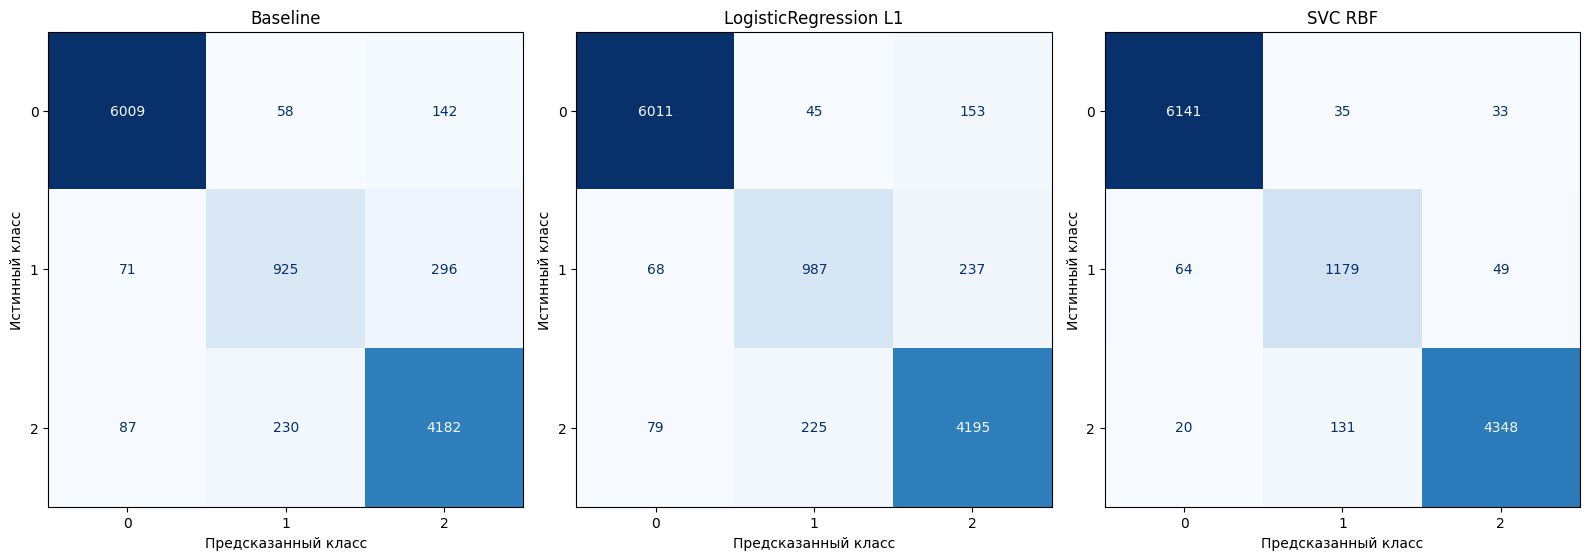

,precision_score,recall_score,f1_score,accuracy_score,class 0 - f1_score,class 1 - f1_score,class 2 - f1_score
Модель,,,,,,,
SVC RBF,0.948,0.956,0.952,0.972,0.988,0.894,0.974
LogisticRegression L1,0.892,0.888,0.890,0.933,0.972,0.774,0.924
Baseline,0.881,0.871,0.876,0.926,0.971,0.739,0.917


In [14]:
models_vs = {'Baseline': bm_pred_train,
             'LogisticRegression L1': best_l1_train,
             'SVC RBF': best_svm_train}

fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize = (16, 14))

for ax, (name, pred) in zip(axes, models_vs.items()):
    ConfusionMatrixDisplay.from_predictions(y_train, pred,
                                            ax = ax,
                                            cmap = 'Blues',
                                            colorbar = False),
    ax.set_title(name),
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    
plt.tight_layout()
plt.show()

comparison_temp = []
for name, pred in models_vs.items():
    class_f1 = f1_score(y_train, pred,
                        labels=[0, 1, 2],
                        average = None,
                        zero_division = 0)
    
    comparison_temp.append({
        'Модель': name,
        'precision_score': round(precision_score(y_train, pred, average = 'macro', zero_division = 0), 3),
        'recall_score': round(recall_score(y_train, pred, average = 'macro', zero_division = 0), 3),
        'f1_score': round(f1_score(y_train, pred, average = 'macro', zero_division = 0), 3),
        'accuracy_score': round(accuracy_score(y_train, pred), 3),
        'class 0 - f1_score': round(class_f1[0], 3),
        'class 1 - f1_score': round(class_f1[1], 3),
        'class 2 - f1_score': round(class_f1[2], 3)
    })
    
comparison_train = pd.DataFrame(comparison_temp).sort_values(by = 'f1_score', ascending = False)
display(comparison_train.set_index('Модель'))

ИТОГОВАЯ МОДЕЛЬ: SVC RBF
F1 macro CV: 0.9448
F1 macro train: 0.952
F1 macro test: 0.943
Метрики на тесте:
              precision    recall  f1-score   support

           0      0.986     0.985     0.985      1552
           1      0.845     0.913     0.878       323
           2      0.976     0.955     0.965      1125

    accuracy                          0.966      3000
   macro avg      0.936     0.951     0.943      3000
weighted avg      0.967     0.966     0.966      3000



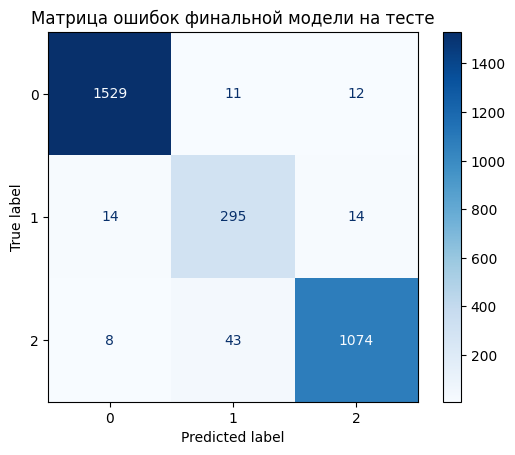

f1_macro > 90%: выполнено
Поклассовые F1: {'Галактика': 0.9855, 'Квазар': 0.878, 'Звезда': 0.9654}


In [15]:
final_test_pred = best_svm.predict(X_test)
print('ИТОГОВАЯ МОДЕЛЬ:', 'SVC RBF')
print('F1 macro CV:', round(best_svm_cv_score, 4))
print('F1 macro train:', round(best_svm_train_score, 4))
print('F1 macro test:', round(f1_score(y_test, final_test_pred, average = 'macro'), 4))
print('Метрики на тесте:')
print(classification_report(y_test, final_test_pred,
                            labels = [0, 1, 2],
                            digits = 3, zero_division = 0))

ConfusionMatrixDisplay.from_predictions(y_test, final_test_pred,
                                        labels = [0, 1, 2],
                                        cmap='Blues')
plt.title('Матрица ошибок финальной модели на тесте')
plt.show()

final_f1 = f1_score(y_test, final_test_pred, average='macro')
final_accuracy = accuracy_score(y_test, final_test_pred)
final_class_f1 = f1_score(y_test, final_test_pred, average = None)

print('f1_macro > 90%:', 'выполнено' if final_f1 > 0.90 else 'не выполнено')
print('Поклассовые F1:', dict(zip(['Галактика', 'Квазар', 'Звезда'], np.round(final_class_f1, 4))))

**Промежуточные выводы**

1. Коротко опишите, сбалансированы ли классы. Если нет, то уточните, какие классы более редкие, какие — частые. Определите, какие классы распознавались хуже и какие методы позволили улучшить качество.
2. Опишите, какие классы модель путала, и возможную причину. Укажите, что помогло решить эту проблему.
3. Запишите итоговую точность полученной модели, и укажите, все ли недостатки удалось устранить.


* Классы распределены неравномерно. Больше всего галактик, меньше всего квазаров. Хуже всего модель распознавала квазары. Использование SVM с RBF-ядром помогло улучшить результаты.

* Чаще всего модель путала звёзды с квазарами. Возможно, это связано со схожими характеристиками объектов. Подбор гиперпараметров и использование SVM помогли уменьшить количество ошибок.

* Итоговая точность модели составила f1-macro — 94.3%. Переобучения не наблюдается. Полностью избавиться от ошибок не удалось, но модель успешно справилась с задачей и превысила требуемую точность 90%.

## Вывод по проекту

Теперь, когда работа над моделью завершена, сформулируйте итоговый вывод по проекту, используя расчитанные ранее результаты.

ИТОГОВЫЙ ВЫВОД

Ответьте на вопросы:
- Какая метрика использовалась для выбора итоговой модели и почему?
- Какая модель в итоге была выбрана и почему? Какие недостатки не удалось устранить даже после улучшений? Каке классы распознаются хуже и почему?
- Какое изменение в разработке классификатора дало наибольший прирост точности?


1. Для выбора модели использовалась метрика f1_macro, так как классы распределены неравномерно. Она позволяет оценить качество распознавания всех классов, включая редкие.

2. Лучшей моделью стала SVM с RBF-ядром, так как она показала самый высокий F1 macro — 94.3%. Однако модель всё ещё иногда путает звёзды с квазарами. Квазары распознаются хуже остальных из-за их малого количества и схожести признаков.

3. Наибольший прирост качества дал переход от логистической регрессии к SVM с RBF-ядром. Это позволило улучшить распознавание всех трёх классов, особенно квазаров.